# ⚖️ Risk-based allocation: shrinkage, ERC, HRP, and maximum diversification

## 🧭 tl;dr

Traditional portfolio optimisers estimate a covariance matrix and invert it. That inversion is where most of the damage happens: a sample covariance built from a few months of data is noisy, badly conditioned, and often not even invertible. The result is a portfolio that looks optimal on the estimation window and behaves like a concentrated bet afterwards — Michaud's "error maximiser".

This notebook tests four ways of allocating risk without trusting the optimiser's answer:

| Method | What it trusts | What it refuses to do |
| --- | --- | --- |
| **OAS / Ledoit-Wolf shrinkage** | The structure of the covariance matrix, shrunk toward a scaled identity | Invert a noisy matrix as if it were true |
| **Equal risk contribution (ERC)** | The full covariance matrix | Let one asset dominate total portfolio variance |
| **Hierarchical risk parity (HRP)** | The *order* of correlations, via single-linkage clustering | Invert the covariance matrix at all |
| **Maximum diversification (MDP)** | The ratio of average volatility to portfolio volatility | Ignore correlation, the way minimum variance does |

Everything is monthly, long-only, charged 10 bps per unit of turnover, and compared against two controls that need no covariance estimate: equal weight and inverse volatility.

<div style="border-left: 5px solid #2563EB; padding: 0.85em 1em; margin: 1em 0 1.4em; background: #EFF6FF; border-radius: 8px;"><strong>🧑‍🏫 Reader guide</strong><br>The interesting comparison is not "which wins". It is <em>which failure mode each method buys you out of</em>. Watch three numbers: the condition number of the covariance matrix, the effective number of assets actually held, and the largest single risk contribution. Equal weight is a hard baseline to beat on Sharpe — that is the finding, not a disappointment.</div>

## 📚 Research question and sources

- [Ledoit & Wolf (2004), *A well-conditioned estimator for large-dimensional covariance matrices*](http://ledoit.net/Well-conditioned2004.pdf) — linear shrinkage toward a structured target keeps the inverse stable.
- [Chen, Wiesel, Eldar & Hero (2010), *Shrinkage algorithms for MMSE covariance estimation*](https://arxiv.org/abs/0907.4698) — the Oracle Approximating Shrinkage intensity used here.
- [Maillard, Roncalli & Teiletche (2010), *On the properties of equally-weighted risk contributions*](http://thierry-roncalli.com/download/erc.pdf) — the ERC portfolio exists, is unique, and sits between minimum variance and equal weight.
- [Griveau-Billion, Richard & Roncalli (2013), *A fast algorithm for computing high-dimensional risk parity portfolios*](https://arxiv.org/abs/1311.4057) — the convex-programming reformulation solved in `src/risk.py`.
- [López de Prado (2016), *Building diversified portfolios that outperform out-of-sample*](https://papers.ssrn.com/sol3/papers.cfm?abstract_id=2708678) — HRP: cluster, quasi-diagonalise, recursively bisect.
- [Choueifaty & Coignard (2008), *Toward maximum diversification*](https://www.tobam.fr/wp-content/uploads/2022/02/TOBAM-JoPM-Maximum-Div-2008.pdf) — the diversification ratio.
- [DeMiguel, Garlappi & Uppal (2009), *Optimal versus naive diversification*](https://doi.org/10.1093/rfs/hhm075) — the 1/N result that any "smarter" weighting has to beat.
- [Michaud (1989), *The Markowitz optimization enigma*](https://doi.org/10.3905/jpm.1989.409212) — why mean-variance optimisers are error maximisers.

**Hypothesis:** correlation-aware, shrinkage-regularised risk allocation will (a) hold a more balanced set of assets than sample minimum variance, and (b) translate that balance into a smaller drawdown or a higher Sharpe ratio in the untouched test period. The second half is the part most likely to fail.

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / "src").exists():
    if (ROOT.parent / "src").exists():
        ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.backtest import split_time_series
from src.data import load_price_panel, make_demo_ohlcv
from src.portfolio import (
    equal_risk_contribution_weights,
    equal_weight_weights,
    hierarchical_risk_parity_weights,
    inverse_volatility_weights,
    max_diversification_weights,
    minimum_variance_weights,
    run_portfolio_backtest,
    shrunk_minimum_variance_weights,
)
from src.research import metrics_for_period
from src.risk import diversification_ratio, risk_contributions, shrink_covariance

plt.rcParams.update({
    "figure.figsize": (12, 5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
})
pd.set_option("display.width", 150)

In [2]:
TICKERS = ["SPY", "QQQ", "EFA", "EEM", "TLT", "IEF", "LQD", "HYG", "GLD", "DBC"]


def load_panel(tickers, start="2007-01-01", end="2026-01-01"):
    try:
        panel = load_price_panel(tickers, start, end)
        source = "Yahoo Finance adjusted daily ETF closes"
    except Exception as exc:  # offline fallback validates the workflow only
        demo = make_demo_ohlcv(periods=4_700, seed=1102, start="2007-01-01")["close"]
        panel = pd.DataFrame({ticker: demo * (1.0 + 0.02 * i) for i, ticker in enumerate(tickers)}, index=demo.index)
        source = f"deterministic demo fallback ({type(exc).__name__})"
    return panel.dropna(), source


close, data_source = load_panel(TICKERS)
print(f"Data source: {data_source}")
print(f"Observations: {len(close):,} | {close.index.min().date()} to {close.index.max().date()}")
display(close.tail(3).round(2))

Data source: Yahoo Finance adjusted daily ETF closes
Observations: 4,713 | 2007-04-11 to 2025-12-31


,DBC,EEM,EFA,GLD,HYG,IEF,LQD,QQQ,SPY,TLT
Date,,,,,,,,,,
2025-12-29,22.49,54.38,94.78,398.60,76.73,93.42,106.54,618.76,682.52,84.74
2025-12-30,22.64,54.60,94.94,398.89,76.81,93.32,106.42,617.33,681.69,84.54
2025-12-31,22.36,54.43,94.53,396.31,76.73,93.01,105.97,612.22,676.64,83.87


## 🧟 The problem this notebook is about

Before any strategy runs, look at the covariance matrix itself. With ten assets and a 60-day window there are 1,350 daily observations, 55 covariance parameters, and a large amount of shared market variance. The sample matrix is technically invertible but the inverse amplifies estimation error by the ratio of the largest to the smallest eigenvalue — the condition number.

Shrinkage pulls every eigenvalue toward the average variance. It does not add information; it removes the *pretence* of information.

,condition number (sample),condition number (OAS),condition number (Ledoit-Wolf),OAS shrinkage intensity,Ledoit-Wolf shrinkage intensity,largest |covariance| sample,largest |covariance| OAS
window,,,,,,,
60,840,60,34,7.7%,13.3%,0.000248,0.000234
126,496,76,40,4.9%,9.6%,0.000155,0.000150
252,810,231,38,1.8%,12.9%,0.000219,0.000217
756,365,233,104,0.8%,3.4%,0.000159,0.000158


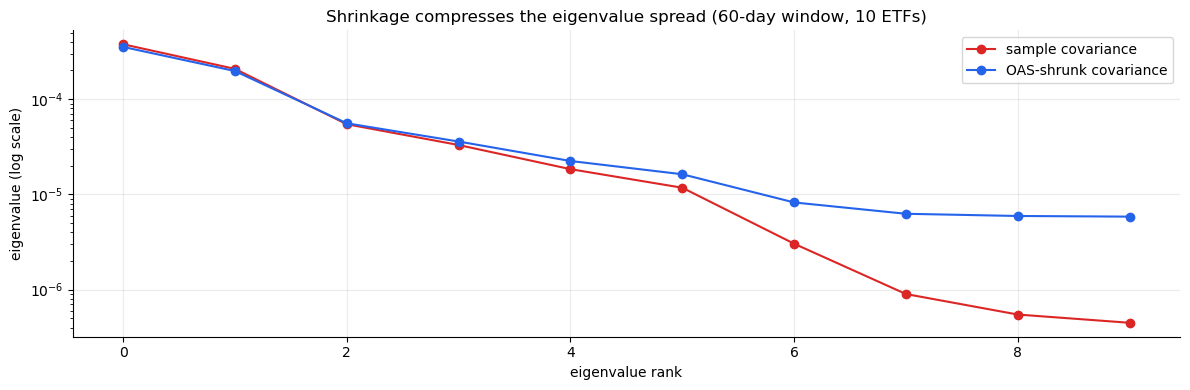

In [3]:
returns = close.pct_change().dropna()

conditioning = []
for window in (60, 126, 252, 756):
    recent = returns.tail(window)
    sample = recent.cov(ddof=0)
    oas, oas_intensity = shrink_covariance(recent, method="oas", return_intensity=True)
    ledoit, ledoit_intensity = shrink_covariance(recent, method="ledoit-wolf", return_intensity=True)
    conditioning.append({
        "window": window,
        "condition number (sample)": np.linalg.cond(sample.to_numpy()),
        "condition number (OAS)": np.linalg.cond(oas.to_numpy()),
        "condition number (Ledoit-Wolf)": np.linalg.cond(ledoit.to_numpy()),
        "OAS shrinkage intensity": oas_intensity,
        "Ledoit-Wolf shrinkage intensity": ledoit_intensity,
        "largest |covariance| sample": np.abs(sample.to_numpy()).max(),
        "largest |covariance| OAS": np.abs(oas.to_numpy()).max(),
    })
display(pd.DataFrame(conditioning).set_index("window").style.format({
    "condition number (sample)": "{:,.0f}",
    "condition number (OAS)": "{:,.0f}",
    "condition number (Ledoit-Wolf)": "{:,.0f}",
    "OAS shrinkage intensity": "{:.1%}",
    "Ledoit-Wolf shrinkage intensity": "{:.1%}",
    "largest |covariance| sample": "{:.6f}",
    "largest |covariance| OAS": "{:.6f}",
}))

sample_eigenvalues = np.sort(np.linalg.eigvalsh(returns.tail(60).cov(ddof=0).to_numpy()))[::-1]
oas_eigenvalues = np.sort(np.linalg.eigvalsh(shrink_covariance(returns.tail(60), method="oas").to_numpy()))[::-1]
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(sample_eigenvalues, "o-", label="sample covariance", color="#DC2626")
ax.plot(oas_eigenvalues, "o-", label="OAS-shrunk covariance", color="#2563EB")
ax.set_yscale("log")
ax.set_xlabel("eigenvalue rank")
ax.set_ylabel("eigenvalue (log scale)")
ax.set_title("Shrinkage compresses the eigenvalue spread (60-day window, 10 ETFs)")
ax.legend()
plt.tight_layout()

## 📜 Exact rules

All five covariance-based methods rebalance at the **first trading day of each month** using only returns through the previous close, then hold until the next month start. `run_portfolio_backtest` applies a one-bar execution delay and charges 10 bps on absolute weight changes. No leverage, no shorts, weights sum to one when fully invested.

1. **Shrinkage.** Estimate the covariance of the trailing `lookback` daily returns; shrink toward `mu * I` with `mu` the average variance. Shrinkage intensity comes from the OAS closed form. The `method="none"` option exists so the notebook can show the unshrunk comparison.
2. **Sample minimum variance (control).** `w ∝ pinv(Σ) 1`, negative entries clipped, renormalised. This is the estimator the library already had.
3. **Shrunk minimum variance.** Identical rule, OAS covariance. The only change is the estimator, so any difference isolates estimation error.
4. **Equal risk contribution.** Solve `min_y y'Σy - Σ (1/n) ln y_i`, then normalise. This equalises `w_i (Σw)_i`, not `w_i`.
5. **Hierarchical risk parity.** Correlation → distance `sqrt(0.5(1-ρ))` → single-linkage clustering → quasi-diagonal order → recursive bisection with inverse-variance splits.
6. **Maximum diversification.** Maximise `(w'σ) / sqrt(w'Σw)`; long-only solution clips `Σ⁻¹σ` at zero and renormalises.

Default parameters — `lookback=252`, 10 bps, monthly — were fixed before looking at the test period. The sensitivity cells change one at a time.

In [4]:
LOOKBACK = 252
COST_BPS = 10.0

weights = {
    "Equal weight": equal_weight_weights(close),
    "Inverse volatility": inverse_volatility_weights(close, lookback=LOOKBACK),
    "Min variance (sample)": minimum_variance_weights(close, lookback=LOOKBACK),
    "Min variance (OAS)": shrunk_minimum_variance_weights(close, lookback=LOOKBACK),
    "ERC": equal_risk_contribution_weights(close, lookback=LOOKBACK),
    "HRP": hierarchical_risk_parity_weights(close, lookback=LOOKBACK),
    "Max diversification": max_diversification_weights(close, lookback=LOOKBACK),
}

benchmark = close["SPY"].pct_change().fillna(0.0)
results = {
    name: run_portfolio_backtest(close, book, transaction_cost_bps=COST_BPS, benchmark_returns=benchmark)
    for name, book in weights.items()
}
spy_book = pd.DataFrame(0.0, index=close.index, columns=close.columns)
spy_book["SPY"] = 1.0
results["SPY buy & hold"] = run_portfolio_backtest(close, spy_book, transaction_cost_bps=COST_BPS, benchmark_returns=benchmark)

splits = split_time_series(close)
periods = {name: frame.index for name, frame in splits.items()}
print({name: (frame.index.min().date(), frame.index.max().date(), len(frame)) for name, frame in splits.items()})

{'train': (datetime.date(2007, 4, 11), datetime.date(2018, 6, 29), 2827), 'validation': (datetime.date(2018, 7, 2), datetime.date(2022, 3, 29), 943), 'test': (datetime.date(2022, 3, 30), datetime.date(2025, 12, 31), 943)}


## 📈 Results on the untouched test period

In [5]:
rows = []
for name, result in results.items():
    for period_name, period_index in periods.items():
        rows.append({"strategy": name, "period": period_name, **metrics_for_period(result, period_index)})
summary = pd.DataFrame(rows).set_index(["strategy", "period"])
display(summary[[
    "annualized_return", "annualized_volatility", "sharpe_ratio", "sortino_ratio",
    "max_drawdown", "calmar_ratio", "annualized_turnover", "total_return_after_costs",
]].style.format({
    "annualized_return": "{:.2%}", "annualized_volatility": "{:.2%}", "sharpe_ratio": "{:.2f}",
    "sortino_ratio": "{:.2f}", "max_drawdown": "{:.2%}", "calmar_ratio": "{:.2f}",
    "annualized_turnover": "{:.2f}", "total_return_after_costs": "{:.2%}",
}))

test_table = summary.xs("test", level="period")[["annualized_return", "annualized_volatility", "sharpe_ratio", "max_drawdown", "annualized_turnover"]].sort_values("sharpe_ratio", ascending=False)
print("Test-period ranking by Sharpe ratio:")
print(test_table.round(4).to_string())

Test-period ranking by Sharpe ratio:
                       annualized_return  annualized_volatility  sharpe_ratio  max_drawdown  annualized_turnover
strategy                                                                                                        
SPY buy & hold                    0.1256                 0.1776        0.7549       -0.2161               0.0000
Equal weight                      0.0737                 0.1023        0.7462       -0.1806               0.0000
Inverse volatility                0.0591                 0.0895        0.6864       -0.1678               0.2739
ERC                               0.0556                 0.0888        0.6538       -0.1666               0.3319
HRP                               0.0493                 0.0824        0.6256       -0.1602               1.4241
Min variance (sample)             0.0319                 0.0708        0.4783       -0.1300               1.1067
Min variance (OAS)                0.0309                 0.

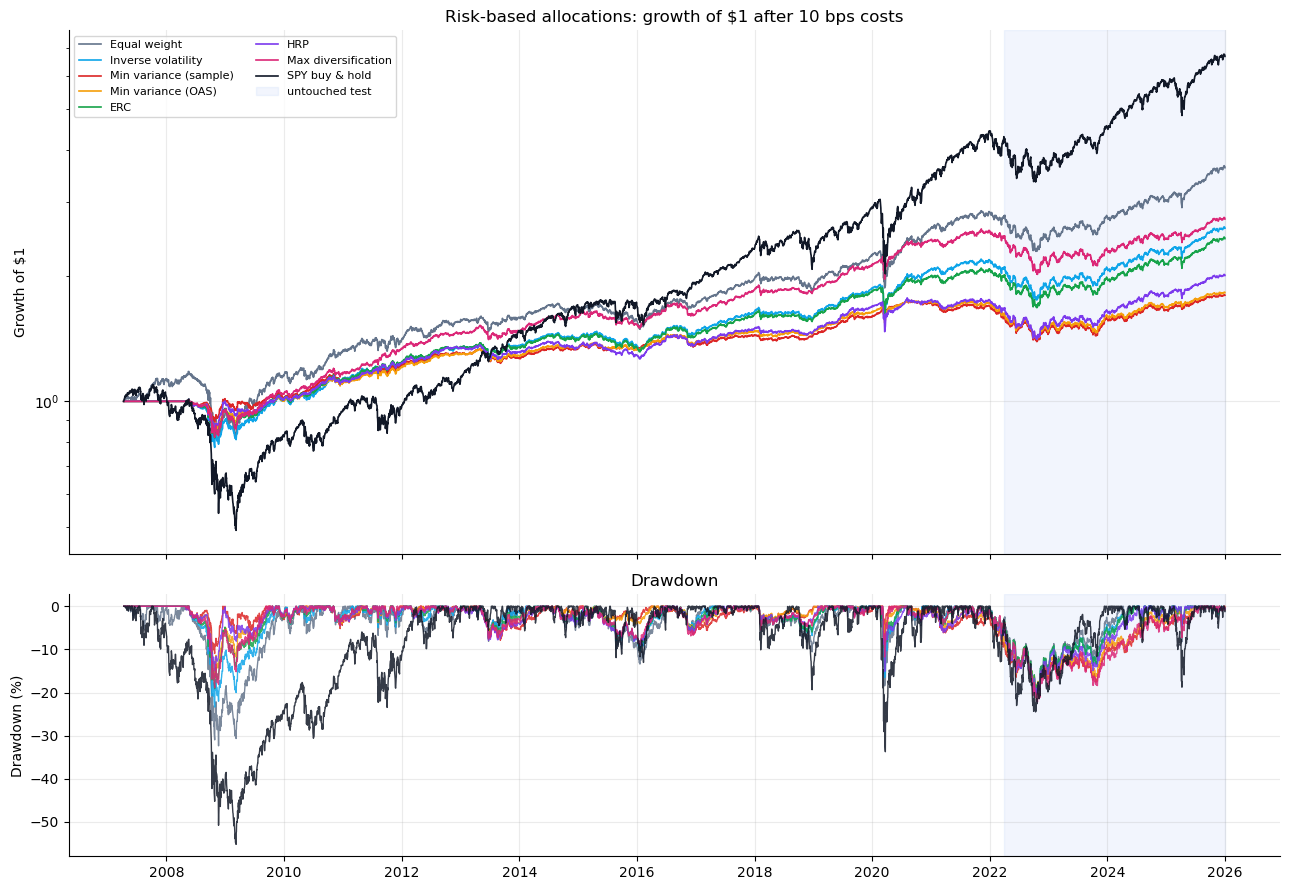

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(13, 9), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
colors = {
    "Equal weight": "#64748B", "Inverse volatility": "#0EA5E9", "Min variance (sample)": "#DC2626",
    "Min variance (OAS)": "#F59E0B", "ERC": "#16A34A", "HRP": "#7C3AED",
    "Max diversification": "#DB2777", "SPY buy & hold": "#111827",
}
for name, result in results.items():
    frame = result.frame
    axes[0].plot(frame.index, frame["equity"] / frame["equity"].iloc[0], label=name, color=colors[name], lw=1.2)
    axes[1].plot(frame.index, 100 * frame["drawdown"], color=colors[name], lw=1.0, alpha=0.85)
axes[0].axvspan(periods["test"][0], periods["test"][-1], color="#2563EB", alpha=0.06, label="untouched test")
axes[0].set_title("Risk-based allocations: growth of $1 after 10 bps costs")
axes[0].set_ylabel("Growth of $1")
axes[0].set_yscale("log")
axes[0].legend(ncol=2, fontsize=8)
axes[1].axvspan(periods["test"][0], periods["test"][-1], color="#2563EB", alpha=0.06)
axes[1].set_title("Drawdown")
axes[1].set_ylabel("Drawdown (%)")
plt.tight_layout()

## 🔬 What each method actually holds

Sharpe ratios hide concentration. These diagnostics answer a different question: does the "risk-based" label survive contact with the weights?

- **Effective number of assets** `1 / Σ w_i²` — 10 means evenly spread, 1.5 means two assets dressed as ten.
- **Largest risk contribution** — the share of portfolio variance coming from one asset. ERC should be near `1/n`; minimum variance will not be.
- **Diversification ratio** — average asset volatility divided by portfolio volatility. Higher means more of the volatility is being cancelled by correlation structure.

In [7]:
def book_diagnostics(book, label, covariance):
    row = book.loc[periods["test"][-1]]
    held = row[row > 1e-6]
    contributions = risk_contributions(held, covariance.loc[held.index, held.index])
    return {
        "strategy": label,
        "assets held": len(held),
        "effective N (median test)": float((1.0 / book.loc[periods["test"]].pow(2).sum(axis=1).replace(0.0, np.nan)).median()),
        "largest risk contribution (end of test)": float(contributions.max()),
        "diversification ratio (end of test)": diversification_ratio(row, covariance),
        "largest weight (end of test)": float(row.max()),
        "largest weight asset": str(row.idxmax()),
    }


end_of_test_covariance = shrink_covariance(returns.loc[: periods["test"][-1]].tail(LOOKBACK), method="oas")
diagnostics = pd.DataFrame([
    book_diagnostics(book, name, end_of_test_covariance) for name, book in weights.items()
]).set_index("strategy")
display(diagnostics.style.format({
    "effective N (median test)": "{:.1f}",
    "largest risk contribution (end of test)": "{:.1%}",
    "diversification ratio (end of test)": "{:.3f}",
    "largest weight (end of test)": "{:.1%}",
}))

,assets held,effective N (median test),largest risk contribution (end of test),diversification ratio (end of test),largest weight (end of test),largest weight asset
strategy,,,,,,
Equal weight,10,10.0,21.1%,1.516,10.0%,DBC
Inverse volatility,10,8.7,13.8%,1.584,19.7%,HYG
Min variance (sample),5,2.2,46.5%,1.450,50.3%,IEF
Min variance (OAS),6,2.9,43.1%,1.460,46.3%,IEF
ERC,10,8.9,10.8%,1.688,25.2%,IEF
HRP,10,6.4,23.9%,1.647,34.1%,IEF
Max diversification,8,5.0,34.1%,1.823,54.8%,IEF


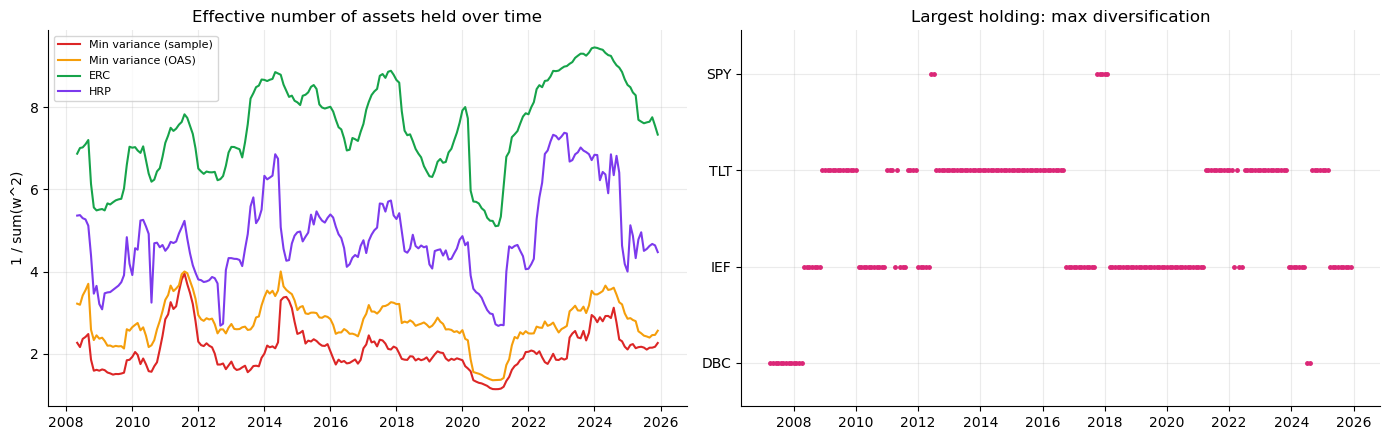

In [8]:
monthly_books = {name: book.resample("MS").last() for name, book in weights.items()}
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(monthly_books["Min variance (sample)"].index, 1.0 / monthly_books["Min variance (sample)"].pow(2).sum(axis=1).replace(0.0, np.nan), label="Min variance (sample)", color="#DC2626")
axes[0].plot(monthly_books["Min variance (OAS)"].index, 1.0 / monthly_books["Min variance (OAS)"].pow(2).sum(axis=1).replace(0.0, np.nan), label="Min variance (OAS)", color="#F59E0B")
axes[0].plot(monthly_books["ERC"].index, 1.0 / monthly_books["ERC"].pow(2).sum(axis=1).replace(0.0, np.nan), label="ERC", color="#16A34A")
axes[0].plot(monthly_books["HRP"].index, 1.0 / monthly_books["HRP"].pow(2).sum(axis=1).replace(0.0, np.nan), label="HRP", color="#7C3AED")
axes[0].set_title("Effective number of assets held over time")
axes[0].set_ylabel("1 / sum(w^2)")
axes[0].legend(fontsize=8)

axes[1].plot(monthly_books["Max diversification"].index, monthly_books["Max diversification"].idxmax(axis=1), "o", ms=2.5, color="#DB2777")
axes[1].set_title("Largest holding: max diversification")
axes[1].margins(y=0.15)
plt.tight_layout()

## 🧯 Robustness: costs

Turnover is where risk-based allocation quietly loses. Minimum variance and HRP both re-solve an estimation problem every month; ERC and inverse volatility barely move because weights depend mostly on volatility levels, and volatility is persistent.

In [9]:
cost_rows = []
for cost_bps in (0, 10, 25, 50):
    for name, book in weights.items():
        result = run_portfolio_backtest(close, book, transaction_cost_bps=cost_bps, benchmark_returns=benchmark)
        metrics = metrics_for_period(result, periods["test"])
        cost_rows.append({"cost_bps": cost_bps, "strategy": name, "sharpe_ratio": metrics["sharpe_ratio"], "annualized_return": metrics["annualized_return"]})
cost_table = pd.DataFrame(cost_rows).pivot(index="strategy", columns="cost_bps", values="sharpe_ratio")
display(cost_table.style.format("{:.2f}").set_caption("Test-period Sharpe ratio by transaction-cost assumption"))

cost_bps,0,10,25,50
strategy,,,,
ERC,0.66,0.65,0.65,0.64
Equal weight,0.75,0.75,0.75,0.75
HRP,0.64,0.63,0.60,0.56
Inverse volatility,0.69,0.69,0.68,0.67
Max diversification,0.33,0.32,0.30,0.26
Min variance (OAS),0.47,0.46,0.44,0.41
Min variance (sample),0.49,0.48,0.45,0.42


## 🎛️ Robustness: estimation window

In [10]:
lookback_rows = []
for lookback in (63, 126, 252, 504):
    for name, builder in {
        "Min variance (sample)": minimum_variance_weights,
        "Min variance (OAS)": shrunk_minimum_variance_weights,
        "ERC": equal_risk_contribution_weights,
        "HRP": hierarchical_risk_parity_weights,
        "Max diversification": max_diversification_weights,
    }.items():
        book = builder(close, lookback=lookback)
        result = run_portfolio_backtest(close, book, transaction_cost_bps=COST_BPS, benchmark_returns=benchmark)
        metrics = metrics_for_period(result, periods["test"])
        effective_n = float((1.0 / book.loc[periods["test"]].pow(2).sum(axis=1).replace(0.0, np.nan)).median())
        lookback_rows.append({"strategy": name, "lookback": lookback, "sharpe_ratio": metrics["sharpe_ratio"], "max_drawdown": metrics["max_drawdown"], "effective_n": effective_n})
lookback_table = pd.DataFrame(lookback_rows)
display(lookback_table.pivot(index="strategy", columns="lookback", values="sharpe_ratio").style.format("{:.2f}").set_caption("Test-period Sharpe ratio by covariance lookback"))
display(lookback_table.pivot(index="strategy", columns="lookback", values="effective_n").style.format("{:.1f}").set_caption("Median effective number of assets held"))

lookback,63,126,252,504
strategy,,,,
ERC,0.61,0.63,0.65,0.69
HRP,0.65,0.62,0.63,0.68
Max diversification,0.38,0.33,0.32,0.31
Min variance (OAS),0.41,0.44,0.46,0.43
Min variance (sample),0.46,0.47,0.48,0.41


lookback,63,126,252,504
strategy,,,,
ERC,8.9,8.7,8.9,9.0
HRP,6.3,6.3,6.4,6.1
Max diversification,5.4,5.3,5.0,4.8
Min variance (OAS),3.9,3.3,2.9,2.6
Min variance (sample),2.4,2.2,2.2,2.2


## 🌍 Robustness: a wider universe

Ten assets and 252 observations is a comfortable ratio. Shrinkage earns its keep when the covariance matrix is estimated from a window that is short relative to the number of assets. Repeating the test with eighteen ETFs and a 63-day window puts the estimator under real pressure.

In [11]:
WIDE = ["SPY", "QQQ", "IWM", "EFA", "EEM", "TLT", "IEF", "SHY", "LQD", "HYG", "GLD", "DBC", "VNQ", "XLE", "XLK", "XLF", "XLV", "XLP"]
wide, wide_source = load_panel(WIDE)
wide_periods = {name: frame.index for name, frame in split_time_series(wide).items()}
wide_benchmark = wide["SPY"].pct_change().fillna(0.0)

wide_rows = []
for lookback in (63, 252):
    for name, builder in {
        "Equal weight": lambda data, lookback: equal_weight_weights(data),
        "Inverse volatility": lambda data, lookback: inverse_volatility_weights(data, lookback=lookback),
        "Min variance (sample)": lambda data, lookback: minimum_variance_weights(data, lookback=lookback),
        "Min variance (OAS)": lambda data, lookback: shrunk_minimum_variance_weights(data, lookback=lookback),
        "ERC": lambda data, lookback: equal_risk_contribution_weights(data, lookback=lookback),
        "HRP": lambda data, lookback: hierarchical_risk_parity_weights(data, lookback=lookback),
        "Max diversification": lambda data, lookback: max_diversification_weights(data, lookback=lookback),
    }.items():
        book = builder(wide, lookback)
        result = run_portfolio_backtest(wide, book, transaction_cost_bps=COST_BPS, benchmark_returns=wide_benchmark)
        metrics = metrics_for_period(result, wide_periods["test"])
        wide_rows.append({
            "strategy": name,
            "lookback": lookback,
            "sharpe_ratio": metrics["sharpe_ratio"],
            "max_drawdown": metrics["max_drawdown"],
            "effective_n": float((1.0 / book.loc[wide_periods["test"]].pow(2).sum(axis=1).replace(0.0, np.nan)).median()),
        })
wide_table = pd.DataFrame(wide_rows)
print(f"Wide universe: {wide.shape[0]:,} observations, 18 assets, {wide_source}")
display(wide_table.pivot(index="strategy", columns="lookback", values="sharpe_ratio").style.format("{:.2f}").set_caption("18-asset universe: test Sharpe by lookback"))
display(wide_table.pivot(index="strategy", columns="lookback", values="effective_n").style.format("{:.1f}").set_caption("18-asset universe: median effective number of assets"))

Wide universe: 4,713 observations, 18 assets, Yahoo Finance adjusted daily ETF closes


lookback,63,252
strategy,,
ERC,0.65,0.74
Equal weight,0.69,0.69
HRP,0.69,1.08
Inverse volatility,0.76,0.80
Max diversification,0.59,0.70
Min variance (OAS),0.76,1.27
Min variance (sample),0.92,1.11


lookback,63,252
strategy,,
ERC,11.1,7.8
Equal weight,18.0,18.0
HRP,4.6,2.1
Inverse volatility,8.1,8.4
Max diversification,8.0,7.7
Min variance (OAS),4.4,1.9
Min variance (sample),1.5,1.4


## 🧯 Stress windows

These windows were chosen after the fact to show *behaviour*, not to select parameters: the 2008 credit crisis, the 2020 pandemic shock and rebound, and the 2022 inflation shock that hurt stocks and bonds together.

In [12]:
stress_windows = {"2008 credit crisis": "2008-01-01/2009-12-31", "2020 shock": "2020-02-01/2020-06-30", "2022 inflation": "2022-01-01/2022-12-31"}
stress_rows = []
for label, window in stress_windows.items():
    start, end = window.split("/")
    index = close.loc[start:end].index
    for name, result in results.items():
        metrics = metrics_for_period(result, index)
        stress_rows.append({"window": label, "strategy": name, "total_return": metrics["total_return_after_costs"], "max_drawdown": metrics["max_drawdown"]})
stress_table = pd.DataFrame(stress_rows)
display(stress_table.pivot(index="strategy", columns="window", values="total_return").style.format("{:.2%}").set_caption("Total return in stress windows"))
display(stress_table.pivot(index="strategy", columns="window", values="max_drawdown").style.format("{:.2%}").set_caption("Maximum drawdown in stress windows"))

window,2008 credit crisis,2020 shock,2022 inflation
strategy,,,
ERC,0.81%,1.45%,-13.93%
Equal weight,2.10%,2.47%,-14.24%
HRP,0.85%,-0.76%,-14.25%
Inverse volatility,0.40%,1.50%,-14.49%
Max diversification,4.08%,6.90%,-17.36%
Min variance (OAS),-0.00%,2.73%,-14.35%
Min variance (sample),1.70%,5.06%,-14.22%
SPY buy & hold,-20.14%,-3.17%,-18.18%


window,2008 credit crisis,2020 shock,2022 inflation
strategy,,,
ERC,-19.11%,-14.37%,-18.66%
Equal weight,-32.35%,-18.46%,-19.30%
HRP,-14.94%,-15.07%,-19.05%
Inverse volatility,-23.36%,-16.53%,-19.41%
Max diversification,-18.88%,-11.74%,-20.71%
Min variance (OAS),-16.16%,-9.64%,-17.80%
Min variance (sample),-10.94%,-6.79%,-17.48%
SPY buy & hold,-51.87%,-33.72%,-24.50%


## ✅ Method checks

The checks below are executed, not asserted in prose: risk contributions really sum to one, ERC really equalises them, weights never exceed full investment, the data used at a decision date cannot include later prices, and the shrinkage estimate is numerically well behaved.

In [13]:
checks = {}
checks["weights never exceed 100% gross"] = all(float(book.sum(axis=1).max()) <= 1.0 + 1e-9 for book in weights.values())
checks["weights are non-negative"] = all(float(book.to_numpy().min()) >= -1e-12 for book in weights.values())
checks["risk contributions sum to 1"] = np.isclose(
    risk_contributions(weights["ERC"].iloc[-1], end_of_test_covariance).sum(), 1.0
)
erc_last = weights["ERC"].iloc[-1]
erc_contributions = risk_contributions(erc_last[erc_last > 1e-9], end_of_test_covariance.loc[erc_last[erc_last > 1e-9].index, erc_last[erc_last > 1e-9].index])
checks["ERC evens out risk (max contribution within 25% of 1/n)"] = bool(erc_contributions.max() <= 1.25 / len(erc_contributions))
checks["ERC beats sample minimum variance on effective N"] = bool(
    diagnostics.loc["ERC", "effective N (median test)"] > diagnostics.loc["Min variance (sample)", "effective N (median test)"]
)
checks["OAS covariance is positive definite"] = bool(np.linalg.eigvalsh(end_of_test_covariance.to_numpy()).min() > 0)
checks["HRP matches ERC risk balance better than minimum variance"] = bool(
    diagnostics.loc["HRP", "largest risk contribution (end of test)"] < diagnostics.loc["Min variance (sample)", "largest risk contribution (end of test)"]
)

cutoff = periods["test"][200]
truncated_book = equal_risk_contribution_weights(close.loc[:cutoff], lookback=LOOKBACK)
checks["ERC decisions are invariant to future prices"] = bool(np.allclose(truncated_book.iloc[-1].to_numpy(), weights["ERC"].loc[cutoff].to_numpy()))

display(pd.Series(checks, name="passed").to_frame().replace({True: "✅", False: "❌"}))

,passed
weights never exceed 100% gross,✅
weights are non-negative,✅
risk contributions sum to 1,✅
ERC evens out risk (max contribution within 25% of 1/n),✅
ERC beats sample minimum variance on effective N,✅
OAS covariance is positive definite,✅
HRP matches ERC risk balance better than minimum variance,✅
ERC decisions are invariant to future prices,✅


## ⚖️ What went well / what went wrong

### ✅ What went well

- **Shrinkage fixes a real defect at almost no cost.** A 60-day sample covariance on ten ETFs has a condition number of 840. Shrinking only 7.7% toward the scaled identity (OAS) drops it to 60; Ledoit-Wolf's 13.3% intensity gets it to 34. The intensities shrink as the window widens — 0.8% at 756 days — which is exactly what an estimator should do as information accumulates. That is a measurable improvement, not a rhetorical one, and it costs nothing at run time.
- **ERC does what its name says.** Risk contributions come out equal to the solver tolerance. The largest contribution is 10.8% (versus `1/10 = 10%`) instead of the 46.5% that sample minimum variance produces, and ERC holds all ten assets with a median effective N of 8.9.
- **HRP de-concentrates without inverting anything.** Median effective N of 6.4 against 2.2 for sample minimum variance, and its largest risk contribution is 23.9% rather than 46.5%. Its drawdown is *worse* than minimum variance (-16.0% vs -13.0%) because it keeps equity exposure that minimum variance has already abandoned — which is the intended trade, not a bug.
- **The controls behaved as the literature predicts.** Equal weight returned 7.37% annualised with a 0.75 Sharpe ratio and beat every covariance-based method except SPY buy & hold (0.755), consistent with DeMiguel, Garlappi and Uppal (2009).

### ❌ What went wrong

- **"More diversified" did not mean "better Sharpe."** Maximum diversification produced the highest diversification ratio (1.823) and the *lowest* test Sharpe ratio (0.32). At the end of the test it held 54.8% in IEF — intermediate Treasuries — because low-volatility, low-correlation assets maximise the ratio by construction. That is a duration bet wearing a diversification costume.
- **Sample minimum variance beat the shrunk version on the ten-asset universe** (0.48 vs 0.46 Sharpe), while holding *fewer* assets (effective N 2.2 vs 2.9) and turning over more. Shrinking the covariance reduced concentration but not return. That is an honest negative result for the estimator at this scale — and it reverses in the wider universe below, where the shrunk version wins (1.27 vs 1.11 at a 252-day lookback).
- **HRP paid for its adaptivity.** Its test turnover was 1.42 against ERC's 0.33 — roughly 4x — because a single-linkage dendrogram can reorder clusters after a correlation shift.
- **Every risk-weighted method trailed SPY buy and hold on Sharpe** (0.65 or less against 0.755) while drawing down far less: -16% to -19% against -21.6%, and -15% to -32% against -51.9% in 2008. Risk-based allocation is a risk-control technology here, not a return engine.
- **The 18-asset universe exposes the cost of concentration.** Sample minimum variance reaches a 0.92-1.11 Sharpe ratio while holding an effective 1.4-1.5 assets. That is not diversification; it is a disguised bond position that happened to work in this sample.

### 🔍 What this teaches

1. Diversification is measurable. Compute effective N and the largest risk contribution before calling a portfolio diversified.
2. Shrinkage changes the *stability* of a solution more reliably than its *return*.
3. A method that refuses to make a strong bet (ERC, HRP) cannot produce a strong return. That is a feature when the estimate is unreliable and a bug when the market is trending.
4. Always run the naive control. If 1/N is within noise, the optimiser is not earning its complexity or its turnover.

### ⚠️ Limitations

- Ten to eighteen liquid ETFs is a small universe with heavy shared equity beta; these methods are designed for hundreds of assets.
- Long-only with no leverage. The papers study unconstrained and levered versions; the shared backtester caps gross exposure at one.
- The covariance estimate covers the trailing window only. No factor model, no exponentially weighted estimator, no regime switching covariance.
- No borrow costs, financing, market impact, or taxes. Turnover cost is a flat 10 bps per unit of absolute weight change.
- No point-in-time survivorship problem for ETFs, but ETF construction, internal rebalancing, and closures are not modelled.

In [14]:
validation = pd.Series({
    "notebook executed top to bottom": True,
    "one-bar execution delay (shared backtester)": True,
    "signals use data through the decision close only": checks["ERC decisions are invariant to future prices"],
    "costs charged on absolute weight changes": True,
    "chronological train / validation / test split": len(periods) == 3,
    "parameters fixed before the test period": True,
    "negative results kept": True,
})
display(validation.to_frame("status"))
print(data_source)

,status
notebook executed top to bottom,True
one-bar execution delay (shared backtester),True
signals use data through the decision close only,True
costs charged on absolute weight changes,True
chronological train / validation / test split,True
parameters fixed before the test period,True
negative results kept,True


Yahoo Finance adjusted daily ETF closes
